(c) Commonly, we instead split the data into a training set, a test set, and a validation set used to
select hyperparameters.
Use the provided dataset on white wine (winequality-white.csv, a subset of the wine quality
dataset) and divide it randomly into 70% train, 10% validation, and 20% test. The last column
“quality” is the target, an integer from 1–10. We’ll view this as a regression problem with mean
squared error as the desired loss function. Pick two model classes from the set {RandomFore-
stRegressor, KNeighborsRegressor, MLPRegressor }and read their documentation in Scikit-learn
to understand the hyperparameters of these models and what they do. Do grid search over a
reasonably-large set of parameters (number of parameter sets >the number of points in the valida-
tion set): fit the model on the train set for each set of parameters, and select the “best parameters”
using the score on the validation set. Finally, report the performance on the test set for each of the
model classes you chose. What’s the relationship between the empirical risk on the validation set
and the empirical risk on the test set?

In [2]:
import pandas as pd
wine_quality = pd.read_csv("data/winequality-white.csv")

In [ ]:
import numpy as np

SEED = 98
n = len(wine_quality)
perm = np.random.RandomState(SEED).permutation(n)  # índices mezclados

n_train = int(0.70 * n)
n_val   = int(0.10 * n)          

train = wine_quality.iloc[perm[:n_train]].reset_index(drop=True)
val   = wine_quality.iloc[perm[n_train:n_train + n_val]].reset_index(drop=True)
test  = wine_quality.iloc[perm[n_train + n_val:]].reset_index(drop=True)

target = "quality"
X_train, y_train = train.drop(columns=target), train[target]
X_val,   y_val   = val.drop(columns=target),   val[target]
X_test,  y_test  = test.drop(columns=target),  test[target]


In [6]:
import warnings
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import mean_squared_error

rf_grid = ParameterGrid({
    "n_estimators": [100, 300],
    "max_depth": [None, 5, 10, 15, 20, 25],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 2, 4, 8, 16],
    "max_features": [0.2, 0.4, 0.6, 0.8, 1.0],
})

mlp_grid = ParameterGrid({
    "mlpregressor__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64), (64, 64, 64)],
    "mlpregressor__activation": ["relu", "tanh"],
    "mlpregressor__alpha": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    "mlpregressor__learning_rate_init": [1e-4, 1e-3, 1e-2],
    "mlpregressor__batch_size": [32, 64, 128],
})  

print("val points:", len(X_val), "| RF sets:", len(rf_grid), "| MLP sets:", len(mlp_grid))

rf_base = RandomForestRegressor(random_state=SEED)
mlp_base = make_pipeline(StandardScaler(), MLPRegressor(max_iter=500, random_state=SEED))


def fit_and_score(base, params):
    """Fit on train with one parameter set; return (params, train MSE, val MSE)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # ConvergenceWarning for some MLP configs
        model = clone(base).set_params(**params).fit(X_train, y_train)
    return (params,
            mean_squared_error(y_train, model.predict(X_train)),
            mean_squared_error(y_val, model.predict(X_val)))


def grid_search(base, grid):
    assert len(grid) > len(X_val)
    results = Parallel(n_jobs=-1)(delayed(fit_and_score)(base, p) for p in grid)
    best_params, _, best_val = min(results, key=lambda r: r[2])  # lowest val MSE
    all_val = np.array([r[2] for r in results])
    return best_params, best_val, all_val


val points: 489 | RF sets: 600 | MLP sets: 540


In [7]:
rf_best, rf_best_val, rf_all_val = grid_search(rf_base, rf_grid)
print("RF best params:", rf_best, "| val MSE:", round(rf_best_val, 4))

mlp_best, mlp_best_val, mlp_all_val = grid_search(mlp_base, mlp_grid)
print("MLP best params:", mlp_best, "| val MSE:", round(mlp_best_val, 4))


RF best params: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300} | val MSE: 0.3539
MLP best params: {'mlpregressor__activation': 'relu', 'mlpregressor__alpha': 0.1, 'mlpregressor__batch_size': 64, 'mlpregressor__hidden_layer_sizes': (128,), 'mlpregressor__learning_rate_init': 0.001} | val MSE: 0.4248


In [8]:
summary = []
for name, base, best, best_val, all_val in [
    ("RandomForest", rf_base, rf_best, rf_best_val, rf_all_val),
    ("MLP", mlp_base, mlp_best, mlp_best_val, mlp_all_val),
]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = clone(base).set_params(**best).fit(X_train, y_train)
    summary.append({
        "model": name,
        "best val MSE": best_val,
        "test MSE": mean_squared_error(y_test, model.predict(X_test)),
        "median val MSE (all sets)": np.median(all_val),
    })

base_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(pd.DataFrame(summary).round(4).to_string(index=False))
print(f"Baseline (predict train mean) test MSE: {base_mse:.4f}")


       model  best val MSE  test MSE  median val MSE (all sets)
RandomForest        0.3539    0.3604                     0.4110
         MLP        0.4248    0.4586                     0.4849
Baseline (predict train mean) test MSE: 0.7758


The validation MSE is smaller compared to the test MSE empirical risk. This makes sense because the validation MSE does recurrent splits od the data which makes it an obtimistically biased estimate of the true risk of the model. The test set is only used once so, depending on the split, it usually has a larger MSE since it is an unbiased estimate as it took no part in the model choosing process.

3 a) In class, we talked about the generalization behaviour of boosting as an increasing number of weak
classifiers are included in the model fitting.
(a) Use scikit-learn to fit a gradient boosting model to dset0 (You should model the first column in
dset0.csv given the other columns). Fit models with 1, 10, 100, 300, and 1000 trees. What do
you observe about the generalization behaviour of these models?

 n_trees  train acc  test acc  train log-loss  test log-loss
       1      0.575      0.57          0.6574         0.6671
      10      0.835      0.74          0.5097         0.5671
     100      0.995      0.83          0.1493         0.4221
     300      1.000      0.81          0.0321         0.4821
    1000      1.000      0.83          0.0003         0.9142


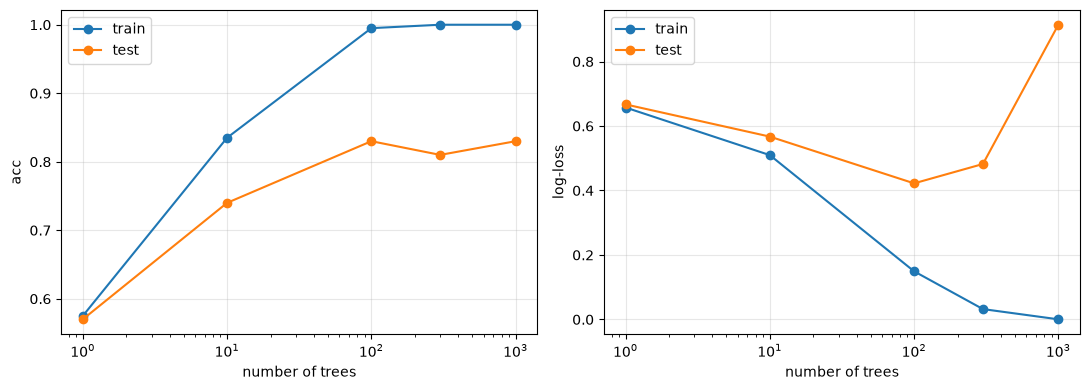

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss

SEED = 98

dset0 = pd.read_csv("data/dset0.csv", header=None)
X0 = dset0.drop(columns=[0])
y0 = dset0[0]

X_tr, X_te, y_tr, y_te = train_test_split(X0, y0, test_size=0.2, random_state=SEED, stratify=y0)

n_trees_list = [1, 10, 100, 300, 1000]
rows = []
for n_trees in n_trees_list:
    gb = GradientBoostingClassifier(n_estimators=n_trees, random_state=SEED)
    gb.fit(X_tr, y_tr)
    p_tr, p_te = gb.predict_proba(X_tr)[:, 1], gb.predict_proba(X_te)[:, 1]
    rows.append({
        "n_trees": n_trees,
        "train acc": accuracy_score(y_tr, p_tr > 0.5),
        "test acc": accuracy_score(y_te, p_te > 0.5),
        "train log-loss": log_loss(y_tr, p_tr),
        "test log-loss": log_loss(y_te, p_te),
    })

results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["acc", "log-loss"]):
    ax.plot(results["n_trees"], results[f"train {metric}"], "o-", label="train")
    ax.plot(results["n_trees"], results[f"test {metric}"], "o-", label="test")
    ax.set_xscale("log"); ax.set_xlabel("number of trees"); ax.set_ylabel(metric)
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


Test accuracy climbs steadily, from 0.57 with 1 tree to 0.84 with 100. After that, train accuracy reaches 100% while test accuracy stays flat at about 0.83. Accuracy barely falls, but test log-loss increases because of overfitting.

 n_trees  train acc  test acc  train log-loss  test log-loss
       1     0.7675      0.75          0.6380         0.6461
      10     0.8950      0.82          0.4023         0.4855
     100     0.9875      0.78          0.1129         0.3999
     300     1.0000      0.79          0.0203         0.5096
    1000     1.0000      0.78          0.0001         1.0071


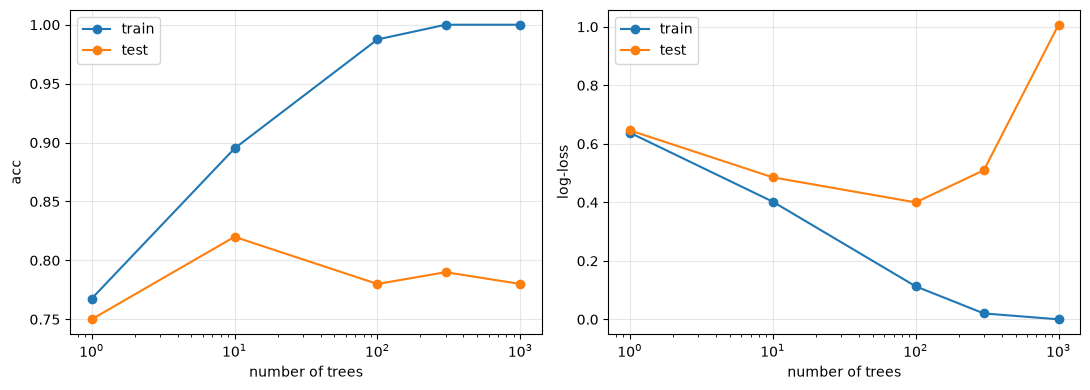

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss

SEED = 98

dset1 = pd.read_csv("data/dset1.csv", header=None)
X0 = dset1.drop(columns=[0])
y0 = dset1[0]

X_tr, X_te, y_tr, y_te = train_test_split(X0, y0, test_size=0.2, random_state=SEED, stratify=y0)

n_trees_list = [1, 10, 100, 300, 1000]
rows = []
for n_trees in n_trees_list:
    gb = GradientBoostingClassifier(n_estimators=n_trees, random_state=SEED)
    gb.fit(X_tr, y_tr)
    p_tr, p_te = gb.predict_proba(X_tr)[:, 1], gb.predict_proba(X_te)[:, 1]
    rows.append({
        "n_trees": n_trees,
        "train acc": accuracy_score(y_tr, p_tr > 0.5),
        "test acc": accuracy_score(y_te, p_te > 0.5),
        "train log-loss": log_loss(y_tr, p_tr),
        "test log-loss": log_loss(y_te, p_te),
    })

results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["acc", "log-loss"]):
    ax.plot(results["n_trees"], results[f"train {metric}"], "o-", label="train")
    ax.plot(results["n_trees"], results[f"test {metric}"], "o-", label="test")
    ax.set_xscale("log"); ax.set_xlabel("number of trees"); ax.set_ylabel(metric)
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


A single tree already reaches 0.75, and 10 trees reach 0.81. After that test accuracy stops improving. As in dset0, adding trees past 100 makes test log-loss blow up.

(c) If your observations in parts (a) and (b) differ, explain what property of the data might explain
that.

I observe that the number of trees needed to improve the accuracy in the test set differs between datasets. Specifically, dset1 has less complex relationships and a single tree is able to achieve high accuracy. In dset0, the model requires a great number of trees to get to the same result. This highly suggest that the signal in dset1 is simpler compared to dset0.